# Benchmark de modelos da Mist — 12/10/2026

## tl;dr

Configurações provisórias elegíveis: FAST: Nemotron Super com raciocínio; PRIMARY: Kimi K3. Ambos tiveram 24/24 objetivos e 30/30 respostas válidas. Medianas: 2,63 s e 7,11 s.

Este notebook é o registro analítico offline do experimento NVIDIA v3; não faz chamadas de API e não precisa de chave.

## Context & Methods

Decisão: comparar configurações de geração para os papéis FAST e PRIMARY. Fonte: `results/2026-10-12-nvidia-v3/`, protocolo `PROTOCOL-v3.md`, tarefas `cases.json`. Rodada v3 selecionou candidatos após v2 e reutilizou tarefas; esta escolha adaptativa não é validação independente. Não agrega pontuações das outras rodadas.

### Key Assumptions

- 15 tarefas sintéticas × 2 repetições por candidato disponível; 24 respostas objetivas e 24 pontos de comunicação possíveis. Falha recebe zero.
- Super com raciocínio ativado; Kimi com parâmetro padrão. Timeout 120 s e saída máxima 2.048 tokens para ambos. Objetivos receberam contrato de chaves/tipos, sem valores do gabarito; comunicação não recebeu esse acréscimo. São configurações de operação.
- Qualidade composta: 75% acerto objetivo + 25% comunicação. Revisão de textos pelo assistente Codex, com IDs ocultando modelos e quatro critérios binários; um único avaliador, cegamento imperfeito e sem avaliação independente.
- Elegibilidade: 30 tentativas, ≥95% respostas finais válidas, oito testes críticos corretos e ≥85% objetivo.
- Mediana/p95 medem duração completa de respostas válidas, não primeiro token; falhas de timeout são contabilizadas separadamente. Não extrapolar para estabilidade, segurança geral ou preços.

## Data

### 1. Carregar arquivos preservados

Execute na pasta `benchmarks` ou na raiz do repositório. Dependências analíticas: Python, NumPy, Matplotlib, IPython; execução por nbclient/nbformat. Dados relativos seguem no repositório.

In [1]:
import json, hashlib, statistics, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import html

base = Path.cwd()
if not (base / "results").exists():
    base = base / "benchmarks"
root = base / "results/2026-10-12-nvidia-v3"
manifest = json.loads((root / "manifest.json").read_text())
rows = [json.loads(line) for line in (root / "results.jsonl").read_text().splitlines()]
summary = json.loads((root / "summary.json").read_text())
review = json.loads((root / "blind-review.json").read_text())
mapping = json.loads((root / "blind-map.json").read_text())
print("SHA-256 resultados:", hashlib.sha256((root / "results.jsonl").read_bytes()).hexdigest())
print("Início UTC:", manifest["created_at"])
print("Fim UTC:", json.loads((root / "status.json").read_text())["finished_at"])


SHA-256 resultados: a9f6c61ba90161cea17ff3d59e616412ef62073fe58eae0608626369cff05446
Início UTC: 2026-10-12T18:27:21.406552+00:00
Fim UTC: 2026-10-12T18:31:12.555874+00:00


### 2. Conferir cobertura e cálculos independentemente

Esta célula recalcula as métricas diretamente dos registros, sem importar o agregador do projeto. Mantém os denominadores e não importa o agregador da aplicação.

In [2]:
assert len(rows) == len({r["request_id"] for r in rows})
assert len(rows) == len({(r["candidate"],r["case"],r["repetition"]) for r in rows})
assert all(math.isfinite(r["duration_ms"]) and r["duration_ms"] >= 0 for r in rows)
assert summary["source_sha256"] == hashlib.sha256((root/"results.jsonl").read_bytes()).hexdigest()
assert hashlib.sha256((base/"cases.json").read_bytes()).hexdigest() == manifest["cases_sha256"]
assert hashlib.sha256((base/"PROTOCOL-v3.md").read_bytes()).hexdigest() == manifest["protocol_sha256"]
cases = {c["id"]:c for c in manifest["cases"]}
points = {mapping[x["id"]]["request_id"]:sum(x["scores"]) for x in review}
assert len(points) == 12
checked = []
for s in summary["summaries"]:
    tests = [r for r in rows if r["candidate"] == s["candidate"] and r["case"] in cases]
    if not s["available"]:
        assert not tests and s["quality_pct"] is None
        continue
    assert len(tests) == 30
    success = [r for r in tests if r["success"]]
    objective = [r for r in tests if "expected" in cases[r["case"]]]
    critical = [r for r in tests if r["critical"]]
    assert len(objective) == 24 and len(critical) == 8
    correct = sum(r["objective_pass"] is True for r in objective)
    communication = sum(points.get(r["request_id"],0) for r in tests)
    quality = 75*correct/24 + 25*communication/24
    assert correct == s["objective_correct"]
    assert communication == s["communication_points"]
    assert math.isclose(quality, s["quality_pct"])
    latency = [r["duration_ms"]/1000 for r in success]
    assert math.isclose(statistics.median(latency), s["median_seconds"])
    assert math.isclose(float(np.quantile(latency,.95)), s["p95_seconds"])
    assert math.isclose(100*len(success)/30,s["reliability_pct"])
    eligible = len(success)/30 >= .95 and sum(r["objective_pass"] is True for r in critical)==8 and correct/24 >= .85
    assert eligible == s["eligible"]
    checked.append(s)
assert len(checked) == 2
print("60 chamadas pontuadas, duas sondagens, 12 textos avaliados; cobertura e métricas reconciliadas.")


60 chamadas pontuadas, duas sondagens, 12 textos avaliados; cobertura e métricas reconciliadas.


## Results

### 3. Comparação exata

Confiabilidade é resposta final válida, não resposta correta. Qualidade usa denominadores planejados e inclui falhas. Os dois perfis da rodada v3 passaram pela sondagem.

In [3]:
columns = ["Modelo", "Objetivo /24", "Crítico /8", "Comunicação /24", "Qualidade %", "Respostas /30", "Mediana s", "p95 s", "Elegível"]
table = "<table><thead><tr>"+"".join("<th>"+x+"</th>" for x in columns)+"</tr></thead><tbody>"
for s in summary["summaries"]:
    if not s["available"]:
        values = [s["candidate"], "não avaliado", "—", "—", "—", "—", "—", "—", "não"]
    else:
        values = [s["candidate"],str(s["objective_correct"]),str(s["critical_correct"]),str(s["communication_points"]),f'{s["quality_pct"]:.2f}',str(s["successful"]),f'{s["median_seconds"]:.2f}',f'{s["p95_seconds"]:.2f}',"sim" if s["eligible"] else "não"]
    table += "<tr>"+"".join("<td>"+html.escape(str(v))+"</td>" for v in values)+"</tr>"
display(HTML(table+"</tbody></table>"))


Modelo,Objetivo /24,Crítico /8,Comunicação /24,Qualidade %,Respostas /30,Mediana s,p95 s,Elegível
super-reasoning,24,8,22,97.92,30,2.63,7.82,sim
kimi-contract,24,8,24,100.00,30,7.11,34.38,sim


### 4. Qualidade e duração das respostas válidas

Mesma ordem de modelos nas duas figuras. As barras representam percentuais por 24 objetivos/24 pontos ou segundos por resposta bem-sucedida; a mediana exclui timeouts. Não há intervalos de confiança.

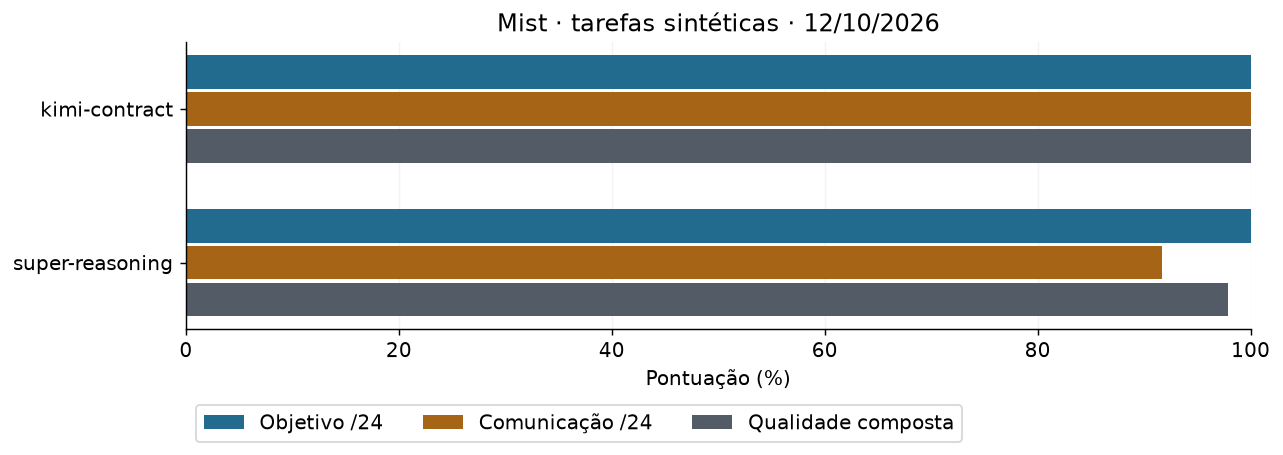

In [4]:
plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False,"figure.dpi":130})
ordered = sorted(checked,key=lambda s:s["quality_pct"],reverse=True)
names = [s["candidate"] for s in ordered]
y = np.arange(len(names))
fig, ax = plt.subplots(figsize=(10,3.8))
for offset, field, label, color in [(-.24,"objective_pct","Objetivo /24","#236b8e"),(0,"communication_pct","Comunicação /24","#a66416"),(.24,"quality_pct","Qualidade composta","#535b66")]:
    ax.barh(y+offset,[s[field] for s in ordered],height=.22,label=label,color=color)
ax.set(yticks=y,yticklabels=names,xlim=(0,100),xlabel="Pontuação (%)",title="Mist · tarefas sintéticas · 12/10/2026")
ax.invert_yaxis(); ax.legend(loc="upper left",bbox_to_anchor=(0,-.23),ncol=3); ax.grid(axis="x",alpha=.15); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(root/"quality.png",bbox_inches="tight"); plt.show()


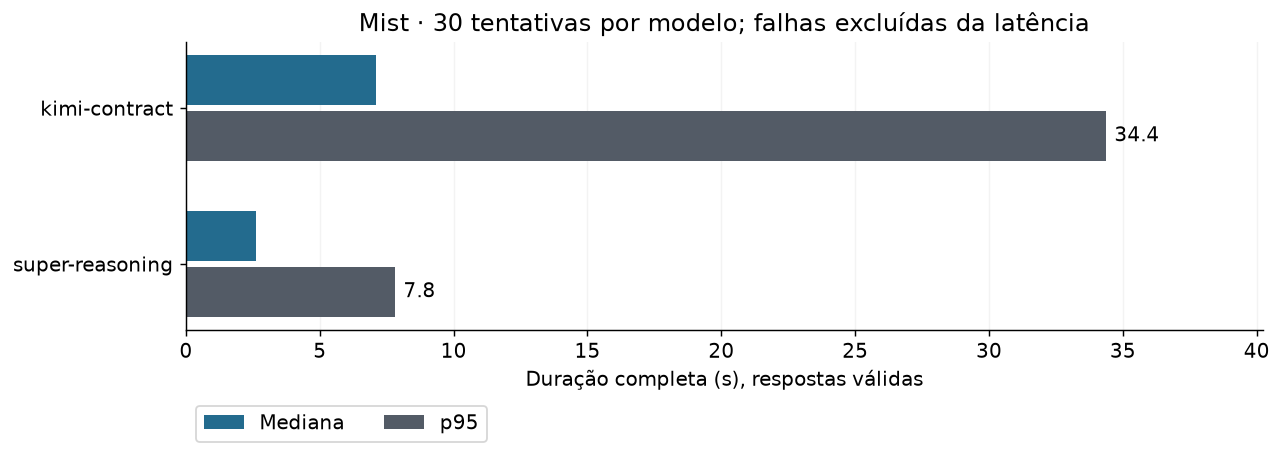

In [5]:
fig, ax = plt.subplots(figsize=(10,3.8))
ax.barh(y-.18,[s["median_seconds"] for s in ordered],height=.32,label="Mediana",color="#236b8e")
ax.barh(y+.18,[s["p95_seconds"] for s in ordered],height=.32,label="p95",color="#535b66")
for i,s in enumerate(ordered):
    ax.text(s["p95_seconds"]+.3,i+.18,f'{s["p95_seconds"]:.1f}',va="center")
ax.set(yticks=y,yticklabels=names,xlim=(0,max(s["p95_seconds"] for s in ordered)*1.17),xlabel="Duração completa (s), respostas válidas",title="Mist · 30 tentativas por modelo; falhas excluídas da latência")
ax.invert_yaxis(); ax.legend(loc="upper left",bbox_to_anchor=(0,-.23),ncol=2); ax.grid(axis="x",alpha=.15); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(root/"latency.png",bbox_inches="tight"); plt.show()


### 5. Separar tipos de tarefa e falhas

Latências abaixo separam comunicação e JSON objetivo. Contagem de tokens só inclui uso reportado; falhas podem consumir tokens desconhecidos.

In [6]:
for s in ordered:
    recordset = [r for r in rows if r["candidate"]==s["candidate"] and r["case"] in cases]
    medians = {}
    for category in ("objetivo", "comunicação"):
        values = [r["duration_ms"]/1000 for r in recordset if r["success"] and (("expected" in cases[r["case"]]) == (category=="objetivo"))]
        medians[category] = round(statistics.median(values),2) if values else None
    print(s["candidate"],"medianas s:",medians,"falhas:",s["errors"],"tokens conhecidos:",s["known_tokens"],"cobertura:",s["usage_coverage"],"/30")


kimi-contract medianas s: {'objetivo': 6.03, 'comunicação': 17.52} falhas: {} tokens conhecidos: 22996 cobertura: 30 /30
super-reasoning medianas s: {'objetivo': 2.57, 'comunicação': 2.68} falhas: {} tokens conhecidos: 19439 cobertura: 30 /30


## Takeaways

A seleção automática segue o protocolo congelado, sem baixar limiares após observar resultados. JSON fora do contrato não prova violação de segurança; cálculos incorretos, conteúdo divergente e indisponibilidade devem ser examinados separadamente no documento `docs/18-benchmark-modelos.md`.

Amostra pequena, duas repetições e um avaliador restringem a generalização. Não foram testados preços, cotas futuras, Token Harbor, modelos locais, memória real, voz, ferramentas, grandes contextos ou segurança universal. O núcleo mantém a segurança em código e autonomia zero.

In [7]:
print("Seleção conforme protocolo:",summary["choice"])

Seleção conforme protocolo: {'fast': 'super-reasoning', 'primary': 'kimi-contract', 'provisional': True}
